# InterviewSense — Laptop-Optimized Speech Quality Pipeline

This notebook is the corrected end-to-end version of the InterviewSense experiment.

## Pipeline
1. Load the laptop-optimized feature dataset/checkpoints.
2. Use 10,000 VCTK + 2,000 NISQA recordings when feature extraction is needed.
3. Repair NISQA MOS labels from the correct per-file metadata CSV.
4. Keep only genuinely labelled NISQA samples for supervised learning.
5. Use group-independent train/validation/test splitting.
6. Train the primary XGBoost model on the project's handcrafted acoustic features.
7. Extract established eGeMAPS features from the same recordings for an external feature baseline.
8. Train the same XGBoost regressor on eGeMAPS.
9. Compare MAE, RMSE and R².
10. Run 5-fold GroupKFold cross-validation on the primary feature representation.

**Important:** NISQA MOS is a human-rated speech-quality target. It is not an interview-fluency or communication-skill score. The experiment therefore validates an acoustic speech-quality baseline rather than claiming a validated interview communication score.


In [1]:
# ============================================================
# SECTION 1: INSTALLATION CHECK
# ============================================================

# Run these in Anaconda Prompt if a package is missing:
#
# pip install numpy pandas scipy scikit-learn librosa soundfile tqdm joblib kagglehub xgboost opensmile matplotlib seaborn
#
# Do NOT run pip installation on every notebook execution.

import os
import re
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

print("Python environment ready.")
print("Working directory:", os.getcwd())


Python environment ready.
Working directory: c:\Users\Karthikeya\Downloads\sp_mouni


In [2]:
# ============================================================
# SECTION 2: IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import librosa
import soundfile as sf

from tqdm.auto import tqdm
from joblib import Parallel, delayed

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Imports successful.")


Imports successful.


## Section 3 — Project configuration

The notebook is intentionally laptop-oriented. The feature extraction stage is capped at 10,000 VCTK files and 2,000 NISQA files. Existing checkpoints are reused, so restarting the notebook does not force feature extraction from zero.


In [3]:
# ============================================================
# SECTION 3: PROJECT CONFIGURATION
# ============================================================

DATASET_LIMITS = {
    "vctk": 10000,
    "nisqa": 2000
}

PROCESS_DATASETS = ["vctk", "nisqa"]

FEATURE_DIR = "feature_checkpoints"
ERROR_DIR = "feature_errors"

os.makedirs(FEATURE_DIR, exist_ok=True)
os.makedirs(ERROR_DIR, exist_ok=True)

CHECKPOINT_EVERY = 250

# Keep this False for the laptop-friendly acoustic feature pipeline.
USE_WHISPER = False

# Conservative CPU worker count. Increase only if your laptop has
# enough RAM/CPU headroom.
N_WORKERS = max(1, min(4, (os.cpu_count() or 2) - 1))

print("Dataset limits:", DATASET_LIMITS)
print("Workers:", N_WORKERS)
print("Whisper:", USE_WHISPER)


Dataset limits: {'vctk': 10000, 'nisqa': 2000}
Workers: 4
Whisper: False


In [4]:
# ============================================================
# SECTION 4: KAGGLE DATASET CONFIGURATION
# ============================================================

DATASET_CONFIG = {
    "vctk": "awsaf49/vctk-sr16k-dataset",
    "speech_accent_archive": "rtatman/speech-accent-archive",
    "santa_barbara": "rtatman/santa-barbara-corpus-of-spoken-american-english",
    "nisqa": "pratt3000/nisqa-corpus"
}

print("Kaggle dataset handles:")
for name, handle in DATASET_CONFIG.items():
    print(f"{name}: {handle}")


Kaggle dataset handles:
vctk: awsaf49/vctk-sr16k-dataset
speech_accent_archive: rtatman/speech-accent-archive
santa_barbara: rtatman/santa-barbara-corpus-of-spoken-american-english
nisqa: pratt3000/nisqa-corpus


In [5]:
# ============================================================
# SECTION 5: DOWNLOAD DATASETS WITH KAGGLEHUB
# ============================================================

import kagglehub

prepared_paths = {}

print("Downloading/reusing VCTK...")
prepared_paths["vctk"] = kagglehub.dataset_download(DATASET_CONFIG["vctk"])
print("VCTK:", prepared_paths["vctk"])

print("\nDownloading/reusing NISQA...")
prepared_paths["nisqa"] = kagglehub.dataset_download(DATASET_CONFIG["nisqa"])
print("NISQA:", prepared_paths["nisqa"])

# The following two datasets are kept in the project configuration,
# but are not required for the supervised MOS experiment.
print("\nOptional reference datasets are configured but not processed:")
print("Speech Accent Archive:", DATASET_CONFIG["speech_accent_archive"])
print("Santa Barbara:", DATASET_CONFIG["santa_barbara"])


Downloading/reusing VCTK...
VCTK: C:\Users\Karthikeya\.cache\kagglehub\datasets\awsaf49\vctk-sr16k-dataset\versions\1

Downloading/reusing NISQA...
NISQA: C:\Users\Karthikeya\.cache\kagglehub\datasets\pratt3000\nisqa-corpus\versions\1

Optional reference datasets are configured but not processed:
Speech Accent Archive: rtatman/speech-accent-archive
Santa Barbara: rtatman/santa-barbara-corpus-of-spoken-american-english


In [6]:
# ============================================================
# SECTION 6: DISCOVER AUDIO FILES
# ============================================================

def find_audio_files(base_path):
    extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}
    found = []
    for root, _, files in os.walk(base_path):
        for file in files:
            if Path(file).suffix.lower() in extensions:
                found.append(os.path.join(root, file))
    return sorted(found)

vctk_audio = find_audio_files(prepared_paths["vctk"])
nisqa_audio = find_audio_files(prepared_paths["nisqa"])

print("VCTK audio files:", len(vctk_audio))
print("NISQA audio files:", len(nisqa_audio))

print("\nFirst VCTK:", vctk_audio[0] if vctk_audio else "NONE")
print("First NISQA:", nisqa_audio[0] if nisqa_audio else "NONE")


VCTK audio files: 43832
NISQA audio files: 27773

First VCTK: C:\Users\Karthikeya\.cache\kagglehub\datasets\awsaf49\vctk-sr16k-dataset\versions\1\wavs\p225_001.wav
First NISQA: C:\Users\Karthikeya\.cache\kagglehub\datasets\pratt3000\nisqa-corpus\versions\1\NISQA_Corpus\NISQA_TEST_FOR\deg\c00001_for_cnv_f_0104_02.wav


## Section 7 — Acoustic feature extraction

The feature representation contains duration/silence statistics, energy, zero-crossing rate, pitch, spectral statistics and MFCC statistics. These are the same general handcrafted acoustic feature families used in the existing feature dataset.


In [7]:
# ============================================================
# SECTION 7: ACOUSTIC FEATURE EXTRACTION
# ============================================================

def safe_stat(values, func, default=0.0):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return float(default)
    try:
        return float(func(values))
    except Exception:
        return float(default)


def extract_speech_features(path, use_whisper=False, whisper_model=None):
    y, sr = librosa.load(path, sr=16000, mono=True)

    if y.size == 0:
        raise ValueError("Empty audio")

    duration = len(y) / sr

    rms = librosa.feature.rms(y=y)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    intervals = librosa.effects.split(y, top_db=30)

    if len(intervals):
        speech_samples = sum(max(0, end - start) for start, end in intervals)
        speech_duration = speech_samples / sr
    else:
        speech_duration = 0.0

    silence_duration = max(0.0, duration - speech_duration)
    speech_ratio = speech_duration / duration if duration > 0 else 0.0

    pauses = []
    if len(intervals) > 1:
        for i in range(1, len(intervals)):
            gap = (intervals[i][0] - intervals[i-1][1]) / sr
            if gap > 0:
                pauses.append(gap)

    pause_count = len(pauses)
    avg_pause_duration = float(np.mean(pauses)) if pauses else 0.0
    max_pause_duration = float(np.max(pauses)) if pauses else 0.0

    f0, voiced_flag, voiced_prob = librosa.pyin(
        y,
        fmin=50,
        fmax=500,
        sr=sr
    )

    pitch = f0[np.isfinite(f0)]
    voiced_frame_ratio = float(np.mean(np.isfinite(f0))) if len(f0) else 0.0

    stft = np.abs(librosa.stft(y))
    spec_centroid = librosa.feature.spectral_centroid(S=stft, sr=sr)[0]
    spec_bandwidth = librosa.feature.spectral_bandwidth(S=stft, sr=sr)[0]

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

    feat = {
        "duration": duration,
        "speech_duration": speech_duration,
        "silence_duration": silence_duration,
        "speech_ratio": speech_ratio,
        "pause_count": pause_count,
        "avg_pause_duration": avg_pause_duration,
        "max_pause_duration": max_pause_duration,

        "rms_mean": safe_stat(rms, np.mean),
        "rms_std": safe_stat(rms, np.std),

        "zcr_mean": safe_stat(zcr, np.mean),
        "zcr_std": safe_stat(zcr, np.std),

        "pitch_mean": safe_stat(pitch, np.mean),
        "pitch_median": safe_stat(pitch, np.median),
        "pitch_std": safe_stat(pitch, np.std),
        "pitch_min": safe_stat(pitch, np.min),
        "pitch_max": safe_stat(pitch, np.max),
        "pitch_range": (
            safe_stat(pitch, np.max) - safe_stat(pitch, np.min)
            if len(pitch) else 0.0
        ),
        "voiced_frame_ratio": voiced_frame_ratio,

        "spec_centroid_mean": safe_stat(spec_centroid, np.mean),
        "spec_centroid_std": safe_stat(spec_centroid, np.std),

        "spec_bandwidth_mean": safe_stat(spec_bandwidth, np.mean),
        "spec_bandwidth_std": safe_stat(spec_bandwidth, np.std)
    }

    for i in range(13):
        feat[f"mfcc_{i+1}_mean"] = safe_stat(mfcc[i], np.mean)
        feat[f"mfcc_{i+1}_std"] = safe_stat(mfcc[i], np.std)

    return feat


print("Feature extractor ready.")


Feature extractor ready.


In [8]:
# ============================================================
# SECTION 8: SAMPLING AND METADATA HELPERS
# ============================================================

def sample_audio_paths(paths, limit, seed=RANDOM_SEED):
    paths = list(paths)
    if limit is None or limit >= len(paths):
        return sorted(paths)

    rng = np.random.default_rng(seed)
    idx = rng.choice(len(paths), size=limit, replace=False)
    return sorted([paths[i] for i in idx])


def build_metadata_lookup(df_meta, speaker_col=None, target_col=None):
    lookup = {}

    if df_meta is None or df_meta.empty:
        return lookup

    key_columns = []

    for col in df_meta.columns:
        name = col.lower()
        if any(token in name for token in [
            "file", "filename", "filepath", "path",
            "audio", "wav", "mp3", "flac",
            "utterance", "sample", "recording", "name"
        ]):
            key_columns.append(col)

    for _, row in df_meta.iterrows():
        candidates = []

        for col in key_columns:
            value = row[col]

            if pd.isna(value):
                continue

            value = str(value).strip()

            if not value:
                continue

            value_lower = value.lower()

            candidates.extend([
                value_lower,
                os.path.basename(value_lower),
                os.path.splitext(os.path.basename(value_lower))[0]
            ])

        metadata = {
            "speaker_id": row.get(speaker_col, "unknown")
            if speaker_col else "unknown",
            "target": row.get(target_col, np.nan)
            if target_col else np.nan
        }

        for key in set(candidates):
            if key:
                lookup.setdefault(key, metadata)

    return lookup


In [9]:
# ============================================================
# SECTION 9: SINGLE RECORD PROCESSOR
# ============================================================

def extract_one_record(path, dataset_name, speaker_id="unknown", target_val=np.nan):
    try:
        feat = extract_speech_features(
            path,
            use_whisper=USE_WHISPER,
            whisper_model=None
        )

        feat["dataset"] = dataset_name
        feat["speaker_id"] = speaker_id
        feat["file_name"] = os.path.basename(path)
        feat["file_key"] = f"{dataset_name}|{os.path.abspath(path)}"
        feat["target"] = target_val

        return feat, None

    except Exception as e:
        return None, {
            "dataset": dataset_name,
            "file_name": os.path.basename(path),
            "path": path,
            "error": repr(e)
        }


In [10]:
# ============================================================
# SECTION 10: CHECKPOINTED DATASET PROCESSING
# ============================================================

def process_dataset(dataset_name, audio_paths):
    key = dataset_name.lower()

    selected = sample_audio_paths(
        audio_paths,
        DATASET_LIMITS.get(key),
        seed=RANDOM_SEED
    )

    print(f"\nProcessing {dataset_name}: {len(selected):,} selected files")

    checkpoint_path = os.path.join(
        FEATURE_DIR,
        f"{key}_features.csv"
    )

    error_path = os.path.join(
        ERROR_DIR,
        f"{key}_errors.csv"
    )

    existing = pd.DataFrame()
    processed_keys = set()

    if os.path.exists(checkpoint_path):
        try:
            existing = pd.read_csv(checkpoint_path)

            if "file_key" in existing.columns:
                processed_keys = set(
                    existing["file_key"].astype(str)
                )

            print(
                f"Resuming {dataset_name}: "
                f"{len(processed_keys):,} files already processed."
            )

        except Exception as e:
            print("Checkpoint read error:", e)

    work_items = []

    for path in selected:
        file_key = f"{dataset_name}|{os.path.abspath(path)}"

        if file_key in processed_keys:
            continue

        file_id = Path(path).stem

        speaker_id = "unknown"

        if key == "vctk":
            m = re.match(r"^(p\d+)_", file_id)
            if m:
                speaker_id = m.group(1)

        work_items.append(
            (path, dataset_name, speaker_id, np.nan)
        )

    if not work_items:
        return existing

    workers = N_WORKERS

    for start in range(
        0,
        len(work_items),
        CHECKPOINT_EVERY
    ):
        batch = work_items[
            start:start + CHECKPOINT_EVERY
        ]

        results = Parallel(
            n_jobs=workers,
            backend="loky"
        )(
            delayed(extract_one_record)(*item)
            for item in tqdm(
                batch,
                desc=f"{dataset_name} batch"
            )
        )

        new_rows = []
        new_errors = []

        for feat, err in results:
            if feat is not None:
                new_rows.append(feat)

            if err is not None:
                new_errors.append(err)

        if new_rows:
            batch_df = pd.DataFrame(new_rows)

            existing = pd.concat(
                [existing, batch_df],
                ignore_index=True
            )

            existing = existing.drop_duplicates(
                subset=["file_key"],
                keep="last"
            )

            existing.to_csv(
                checkpoint_path,
                index=False
            )

        if new_errors:
            err_df = pd.DataFrame(new_errors)

            if os.path.exists(error_path):
                old_err = pd.read_csv(error_path)
                err_df = pd.concat(
                    [old_err, err_df],
                    ignore_index=True
                )

            err_df.to_csv(
                error_path,
                index=False
            )

        print(
            f"Checkpoint saved: {len(existing):,} successful files."
        )

    return existing


In [11]:
# ============================================================
# SECTION 11: LOAD EXISTING FEATURE CHECKPOINTS OR EXTRACT
# ============================================================

vctk_checkpoint = os.path.join(
    FEATURE_DIR,
    "vctk_features.csv"
)

nisqa_checkpoint = os.path.join(
    FEATURE_DIR,
    "nisqa_features.csv"
)

frames = []

if os.path.exists(vctk_checkpoint):
    vctk_df = pd.read_csv(vctk_checkpoint)
    frames.append(vctk_df)
    print("Loaded VCTK checkpoint:", vctk_df.shape)
else:
    vctk_df = process_dataset(
        "VCTK",
        vctk_audio
    )
    frames.append(vctk_df)

if os.path.exists(nisqa_checkpoint):
    nisqa_df = pd.read_csv(nisqa_checkpoint)
    frames.append(nisqa_df)
    print("Loaded NISQA checkpoint:", nisqa_df.shape)
else:
    nisqa_df = process_dataset(
        "NISQA",
        nisqa_audio
    )
    frames.append(nisqa_df)

df_features = pd.concat(
    [x for x in frames if not x.empty],
    ignore_index=True
).drop_duplicates(
    subset=["file_key"]
).reset_index(drop=True)

print("\nFeature dataset:")
print(df_features.shape)
print(df_features["dataset"].value_counts())


Loaded VCTK checkpoint: (10000, 53)
Loaded NISQA checkpoint: (2000, 53)

Feature dataset:
(12000, 53)
dataset
VCTK     10000
NISQA     2000
Name: count, dtype: int64


## Section 12 — Correct NISQA MOS label repair

The earlier notebook problem was caused by using generic metadata matching. The correct NISQA metadata file contains `mos` and `filepath_deg`. We therefore explicitly locate the NISQA per-file CSV and match the extracted recording by its basename.

This is the critical repair that should produce the previously observed **1,036 matched MOS labels** from the 2,000 processed NISQA recordings.


In [12]:
# ============================================================
# SECTION 12: FIND CORRECT NISQA LABEL CSV
# ============================================================

def find_nisqa_label_csv(base_path):
    candidates = []

    for root, _, files in os.walk(base_path):
        for file in files:
            if not file.lower().endswith(".csv"):
                continue

            path = os.path.join(root, file)

            try:
                head = pd.read_csv(path, nrows=5)
                cols = {c.lower() for c in head.columns}

                if "mos" in cols and (
                    "filepath_deg" in cols
                    or "file" in cols
                    or "filename" in cols
                    or "filepath" in cols
                ):
                    candidates.append(path)

            except Exception:
                pass

    if not candidates:
        raise FileNotFoundError(
            "Could not find NISQA metadata CSV containing MOS and a file-path column."
        )

    # Prefer the canonical corpus CSV when available.
    candidates.sort(
        key=lambda p: (
            "nisqa_corpus_file.csv" not in os.path.basename(p).lower(),
            len(p)
        )
    )

    return candidates[0]


nisqa_label_csv = find_nisqa_label_csv(
    prepared_paths["nisqa"]
)

print("NISQA label CSV:")
print(nisqa_label_csv)


NISQA label CSV:
C:\Users\Karthikeya\.cache\kagglehub\datasets\pratt3000\nisqa-corpus\versions\1\NISQA_Corpus\NISQA_corpus_file.csv


In [13]:
# ============================================================
# SECTION 13: REPAIR NISQA MOS LABELS AND CREATE GROUP IDs
# ============================================================

meta = pd.read_csv(nisqa_label_csv)

path_col = next(
    c for c in meta.columns
    if c.lower() in {
        "filepath_deg",
        "filepath",
        "file",
        "filename"
    }
)

meta["__file_name"] = (
    meta[path_col]
    .astype(str)
    .map(lambda x: os.path.basename(x).lower())
)

meta["mos"] = pd.to_numeric(
    meta["mos"],
    errors="coerce"
)

mos_lookup = (
    meta.dropna(subset=["mos"])
    .drop_duplicates("__file_name")
    .set_index("__file_name")["mos"]
    .to_dict()
)

nisqa_mask = (
    df_features["dataset"]
    .astype(str)
    .str.upper()
    .eq("NISQA")
)

df_features.loc[
    nisqa_mask,
    "target"
] = (
    df_features.loc[
        nisqa_mask,
        "file_name"
    ]
    .astype(str)
    .str.lower()
    .map(mos_lookup)
)

# Group NISQA recordings by the underlying source clip.
# Example:
# c00001_for_cnv_f_0104_02.wav
# becomes
# c00001_for_cnv_f_0104
df_features["group_id"] = (
    df_features["speaker_id"]
    .astype(str)
)

nisqa_groups = (
    df_features.loc[
        nisqa_mask,
        "file_name"
    ]
    .astype(str)
    .str.replace(
        r"_\d+\.wav$",
        "",
        regex=True
    )
)

df_features.loc[
    nisqa_mask,
    "group_id"
] = nisqa_groups

df_features.to_csv(
    "features_all.csv",
    index=False
)

print("=" * 70)
print("NISQA LABEL MAPPING RESULT")
print("=" * 70)

print("Total NISQA feature rows:",
      int(nisqa_mask.sum()))

print(
    "Successfully matched MOS:",
    int(
        df_features.loc[
            nisqa_mask,
            "target"
        ].notna().sum()
    )
)

print(
    "Missing MOS:",
    int(
        df_features.loc[
            nisqa_mask,
            "target"
        ].isna().sum()
    )
)

labelled = df_features.loc[
    nisqa_mask & df_features["target"].notna()
]

print(
    "MOS range:",
    f"{labelled['target'].min():.3f} -> "
    f"{labelled['target'].max():.3f}"
)

print(
    "MOS mean:",
    f"{labelled['target'].mean():.3f}"
)

print(
    "Unique groups:",
    labelled["group_id"].nunique()
)


NISQA LABEL MAPPING RESULT
Total NISQA feature rows: 2000
Successfully matched MOS: 0
Missing MOS: 2000
MOS range: nan -> nan
MOS mean: nan
Unique groups: 0


In [31]:
# ============================================================
# SECTION 14: BUILD LABELLED SUPERVISED DATASET
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Find the correct NISQA metadata CSV
# ------------------------------------------------------------

def find_nisqa_label_csv(base_path):
    candidates = []

    for root, _, files in os.walk(base_path):
        for file in files:
            if not file.lower().endswith(".csv"):
                continue

            path = os.path.join(root, file)

            try:
                head = pd.read_csv(path, nrows=5)
                cols = {str(c).lower() for c in head.columns}

                if (
                    "mos" in cols
                    and (
                        "filepath_deg" in cols
                        or "file" in cols
                        or "filename" in cols
                        or "filepath" in cols
                    )
                ):
                    candidates.append(path)

            except Exception:
                continue

    if not candidates:
        raise FileNotFoundError(
            "Could not find the NISQA CSV containing MOS labels."
        )

    return candidates[0]


# ------------------------------------------------------------
# 2. Load NISQA metadata
# ------------------------------------------------------------

nisqa_csv = find_nisqa_label_csv(
    prepared_paths["nisqa"]
)

nisqa_meta = pd.read_csv(nisqa_csv)

print("=" * 70)
print("NISQA METADATA")
print("=" * 70)
print("CSV:", nisqa_csv)
print("Rows:", len(nisqa_meta))
print("Columns:", list(nisqa_meta.columns))

if "mos" not in nisqa_meta.columns:
    raise RuntimeError(
        "NISQA metadata does not contain a 'mos' column."
    )

nisqa_meta["mos"] = pd.to_numeric(
    nisqa_meta["mos"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. Determine the filename column
# ------------------------------------------------------------

possible_path_cols = [
    "filepath_deg",
    "filepath",
    "file",
    "filename"
]

path_col = None

for col in possible_path_cols:
    if col in nisqa_meta.columns:
        path_col = col
        break

if path_col is None:
    raise RuntimeError(
        "Could not identify the NISQA degraded-audio filename column."
    )

# ------------------------------------------------------------
# 4. Create robust filename -> MOS lookup
# ------------------------------------------------------------

nisqa_meta["__filename_key"] = (
    nisqa_meta[path_col]
    .astype(str)
    .map(lambda x: os.path.basename(x).strip().lower())
)

nisqa_meta["__stem_key"] = (
    nisqa_meta["__filename_key"]
    .map(lambda x: os.path.splitext(x)[0])
)

mos_by_filename = (
    nisqa_meta
    .dropna(subset=["mos"])
    .drop_duplicates("__filename_key")
    .set_index("__filename_key")["mos"]
    .to_dict()
)

mos_by_stem = (
    nisqa_meta
    .dropna(subset=["mos"])
    .drop_duplicates("__stem_key")
    .set_index("__stem_key")["mos"]
    .to_dict()
)

print("NISQA MOS labels available:", len(mos_by_filename))


# ------------------------------------------------------------
# 5. Repair targets inside df_features
# ------------------------------------------------------------

nisqa_mask = (
    df_features["dataset"]
    .astype(str)
    .str.upper()
    .eq("NISQA")
)

df_features["target"] = pd.to_numeric(
    df_features["target"],
    errors="coerce"
)

# Match using file_name
filename_keys = (
    df_features["file_name"]
    .astype(str)
    .map(lambda x: os.path.basename(x).strip().lower())
)

stem_keys = (
    filename_keys
    .map(lambda x: os.path.splitext(x)[0])
)

filename_targets = filename_keys.map(mos_by_filename)
stem_targets = stem_keys.map(mos_by_stem)

# Filename match first, stem match second
df_features.loc[nisqa_mask, "target"] = (
    filename_targets[nisqa_mask]
    .combine_first(stem_targets[nisqa_mask])
)

# ------------------------------------------------------------
# 6. Create group_id
# ------------------------------------------------------------

df_features["group_id"] = (
    df_features["speaker_id"]
    .astype(str)
)

# NISQA files with the same source recording should stay
# in the same split.
nisqa_group = (
    df_features.loc[nisqa_mask, "file_name"]
    .astype(str)
    .str.replace(
        r"_\d+\.wav$",
        "",
        regex=True
    )
)

df_features.loc[nisqa_mask, "group_id"] = nisqa_group


# ------------------------------------------------------------
# 7. Report label matching
# ------------------------------------------------------------

nisqa_labelled = (
    df_features.loc[nisqa_mask, "target"]
    .notna()
    .sum()
)

nisqa_total = nisqa_mask.sum()

print()
print("=" * 70)
print("NISQA LABEL REPAIR RESULT")
print("=" * 70)

print(f"Total NISQA feature rows : {nisqa_total:,}")
print(f"Matched MOS labels       : {nisqa_labelled:,}")
print(f"Missing MOS labels       : {nisqa_total - nisqa_labelled:,}")

if nisqa_labelled > 0:
    print(
        f"MOS range                : "
        f"{df_features.loc[nisqa_mask, 'target'].min():.3f} -> "
        f"{df_features.loc[nisqa_mask, 'target'].max():.3f}"
    )

    print(
        f"MOS mean                 : "
        f"{df_features.loc[nisqa_mask, 'target'].mean():.3f}"
    )

    print(
        f"MOS median               : "
        f"{df_features.loc[nisqa_mask, 'target'].median():.3f}"
    )


# ------------------------------------------------------------
# 8. Build supervised dataset
# ------------------------------------------------------------

df_train_all = df_features[
    nisqa_mask &
    df_features["target"].notna()
].copy()

df_train_all["target"] = pd.to_numeric(
    df_train_all["target"],
    errors="coerce"
)

df_train_all = (
    df_train_all
    .dropna(subset=["target", "group_id"])
    .reset_index(drop=True)
)

if len(df_train_all) < 100:
    raise RuntimeError(
        f"Only {len(df_train_all)} labelled NISQA rows found. "
        "MOS label mapping must be fixed before training."
    )


# ------------------------------------------------------------
# 9. Select numeric acoustic features
# ------------------------------------------------------------

feature_exclude = {
    "dataset",
    "speaker_id",
    "file_name",
    "file_key",
    "target",
    "group_id",
    "transcript"
}

feature_cols = [
    c
    for c in df_train_all.columns
    if c not in feature_exclude
    and pd.api.types.is_numeric_dtype(
        df_train_all[c]
    )
]

if not feature_cols:
    raise RuntimeError(
        "No numeric acoustic features were found."
    )


# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print()
print("=" * 70)
print("SUPERVISED DATASET READY")
print("=" * 70)

print(f"Rows       : {len(df_train_all):,}")
print(f"Features   : {len(feature_cols)}")
print(f"Groups     : {df_train_all['group_id'].nunique():,}")
print(f"MOS min    : {df_train_all['target'].min():.3f}")
print(f"MOS max    : {df_train_all['target'].max():.3f}")
print(f"MOS mean   : {df_train_all['target'].mean():.3f}")
print(f"MOS median : {df_train_all['target'].median():.3f}")

print()
print("Feature columns:")
print(feature_cols)

# Save repaired feature dataset
df_features.to_csv(
    "features_all_repaired.csv",
    index=False
)

print()
print("Saved: features_all_repaired.csv")

NISQA METADATA
CSV: C:\Users\Karthikeya\.cache\kagglehub\datasets\pratt3000\nisqa-corpus\versions\1\NISQA_Corpus\NISQA_corpus_file.csv
Rows: 14432
Columns: ['db', 'con', 'file', 'con_description', 'filename_deg', 'filename_ref', 'source', 'lang', 'votes', 'mos', 'noi', 'col', 'dis', 'loud', 'noi_std', 'col_std', 'dis_std', 'loud_std', 'mos_std', 'filepath_deg', 'filepath_ref']
NISQA MOS labels available: 14432

NISQA LABEL REPAIR RESULT
Total NISQA feature rows : 2,000
Matched MOS labels       : 1,036
Missing MOS labels       : 964
MOS range                : 1.000 -> 5.000
MOS mean                 : 2.908
MOS median               : 2.800

SUPERVISED DATASET READY
Rows       : 1,036
Features   : 48
Groups     : 1,036
MOS min    : 1.000
MOS max    : 5.000
MOS mean   : 2.908
MOS median : 2.800

Feature columns:
['duration', 'speech_duration', 'silence_duration', 'speech_ratio', 'pause_count', 'avg_pause_duration', 'max_pause_duration', 'rms_mean', 'rms_std', 'zcr_mean', 'zcr_std', 'pitch_

In [17]:
# ============================================================
# SECTION 15: GROUP-INDEPENDENT TRAIN / VALIDATION / TEST SPLIT
# ============================================================

groups = df_train_all["group_id"].astype(str)

if groups.nunique() < 3:
    raise RuntimeError(
        "At least 3 distinct groups are required."
    )

# 70% train / 30% temporary
gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_SEED
)

train_idx, temp_idx = next(
    gss1.split(
        df_train_all,
        groups=groups
    )
)

train_df = df_train_all.iloc[
    train_idx
].copy()

temp_df = df_train_all.iloc[
    temp_idx
].copy()

# Split temporary set equally into validation and test.
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=RANDOM_SEED
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        groups=temp_df["group_id"].astype(str)
    )
)

val_df = temp_df.iloc[
    val_idx
].copy()

test_df = temp_df.iloc[
    test_idx
].copy()

train_groups = set(
    train_df["group_id"].astype(str)
)

val_groups = set(
    val_df["group_id"].astype(str)
)

test_groups = set(
    test_df["group_id"].astype(str)
)

assert not train_groups.intersection(val_groups)
assert not train_groups.intersection(test_groups)
assert not val_groups.intersection(test_groups)

print("=" * 70)
print("GROUP-INDEPENDENT SPLIT")
print("=" * 70)

print(
    f"Train      : {len(train_df):,} samples | "
    f"{len(train_groups):,} groups"
)

print(
    f"Validation : {len(val_df):,} samples | "
    f"{len(val_groups):,} groups"
)

print(
    f"Test       : {len(test_df):,} samples | "
    f"{len(test_groups):,} groups"
)

print("\nGroup leakage test: PASSED")


GROUP-INDEPENDENT SPLIT
Train      : 725 samples | 725 groups
Validation : 155 samples | 155 groups
Test       : 156 samples | 156 groups

Group leakage test: PASSED


In [18]:
# ============================================================
# SECTION 16: PREPARE PRIMARY ACOUSTIC FEATURES
# ============================================================

X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df["target"].astype(float)
y_val = val_df["target"].astype(float)
y_test = test_df["target"].astype(float)

X_train = X_train.replace(
    [np.inf, -np.inf],
    np.nan
)

X_val = X_val.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test = X_test.replace(
    [np.inf, -np.inf],
    np.nan
)

train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


X_train: (725, 48)
X_val: (155, 48)
X_test: (156, 48)


In [19]:
# ============================================================
# SECTION 17: TRAIN PRIMARY XGBOOST MODEL
# ============================================================

primary_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=RANDOM_SEED,
    n_jobs=-1
)

primary_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Primary XGBoost model trained.")


Primary XGBoost model trained.


In [20]:
# ============================================================
# SECTION 18: PRIMARY MODEL EVALUATION
# ============================================================

primary_pred = primary_model.predict(X_test)

primary_mae = mean_absolute_error(
    y_test,
    primary_pred
)

primary_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        primary_pred
    )
)

primary_r2 = r2_score(
    y_test,
    primary_pred
)

print("=" * 70)
print("PRIMARY MODEL RESULTS")
print("=" * 70)

print(f"MAE  : {primary_mae:.4f}")
print(f"RMSE : {primary_rmse:.4f}")
print(f"R²   : {primary_r2:.4f}")


PRIMARY MODEL RESULTS
MAE  : 0.5912
RMSE : 0.7240
R²   : 0.4797


## Section 19 — External feature baseline: eGeMAPS

eGeMAPS is an established speech-feature representation. We use it as a feature-level comparison against the project's handcrafted acoustic representation.

The same labelled recordings and the same XGBoost regression family are used so the feature representation is the main experimental difference.


In [22]:
# ============================================================
# SECTION 19: INITIALIZE eGeMAPS
# ============================================================

import opensmile

smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals
)

print("eGeMAPSv02 initialized.")


eGeMAPSv02 initialized.


In [23]:
# ============================================================
# SECTION 20: EXTRACT eGeMAPS FROM THE SAME RECORDINGS
# ============================================================

def get_audio_path(row):
    file_key = str(row["file_key"])

    if "|" in file_key:
        path = file_key.split("|", 1)[1]
        if os.path.exists(path):
            return path

    return None


def extract_egemaps(df, checkpoint_name):
    checkpoint_path = os.path.join(
        FEATURE_DIR,
        checkpoint_name
    )

    if os.path.exists(checkpoint_path):
        cached = pd.read_csv(checkpoint_path)
        print("Loaded eGeMAPS checkpoint:", cached.shape)
        return cached

    rows = []
    errors = []

    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc="eGeMAPS"
    ):
        try:
            path = get_audio_path(row)

            if path is None:
                raise FileNotFoundError(
                    f"Audio path unavailable for {row['file_name']}"
                )

            features = smile.process_file(path)

            values = features.iloc[0].to_dict()

            values["target"] = float(row["target"])
            values["group_id"] = row["group_id"]
            values["file_key"] = row["file_key"]

            rows.append(values)

        except Exception as e:
            errors.append({
                "file_key": row["file_key"],
                "file_name": row["file_name"],
                "error": repr(e)
            })

    result = pd.DataFrame(rows)

    result.to_csv(
        checkpoint_path,
        index=False
    )

    if errors:
        pd.DataFrame(errors).to_csv(
            os.path.join(
                ERROR_DIR,
                checkpoint_name.replace(
                    ".csv",
                    "_errors.csv"
                )
            ),
            index=False
        )

    return result


eg_train = extract_egemaps(
    train_df,
    "egemaps_train.csv"
)

eg_val = extract_egemaps(
    val_df,
    "egemaps_val.csv"
)

eg_test = extract_egemaps(
    test_df,
    "egemaps_test.csv"
)

print("Train:", eg_train.shape)
print("Val:", eg_val.shape)
print("Test:", eg_test.shape)


eGeMAPS:   0%|          | 0/725 [00:00<?, ?it/s]

eGeMAPS:   0%|          | 0/155 [00:00<?, ?it/s]

eGeMAPS:   0%|          | 0/156 [00:00<?, ?it/s]

Train: (725, 91)
Val: (155, 91)
Test: (156, 91)


In [24]:
# ============================================================
# SECTION 21: TRAIN eGeMAPS + XGBOOST COMPARISON MODEL
# ============================================================

eg_feature_cols = [
    c for c in eg_train.columns
    if c not in {
        "target",
        "group_id",
        "file_key"
    }
    and pd.api.types.is_numeric_dtype(
        eg_train[c]
    )
]

X_eg_train = eg_train[
    eg_feature_cols
].replace(
    [np.inf, -np.inf],
    np.nan
)

X_eg_val = eg_val[
    eg_feature_cols
].replace(
    [np.inf, -np.inf],
    np.nan
)

X_eg_test = eg_test[
    eg_feature_cols
].replace(
    [np.inf, -np.inf],
    np.nan
)

eg_medians = X_eg_train.median()

X_eg_train = X_eg_train.fillna(eg_medians)
X_eg_val = X_eg_val.fillna(eg_medians)
X_eg_test = X_eg_test.fillna(eg_medians)

y_eg_train = eg_train["target"].astype(float)
y_eg_val = eg_val["target"].astype(float)
y_eg_test = eg_test["target"].astype(float)

eg_model = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=RANDOM_SEED,
    n_jobs=-1
)

eg_model.fit(
    X_eg_train,
    y_eg_train,
    eval_set=[(X_eg_val, y_eg_val)],
    verbose=False
)

eg_pred = eg_model.predict(
    X_eg_test
)

eg_mae = mean_absolute_error(
    y_eg_test,
    eg_pred
)

eg_rmse = np.sqrt(
    mean_squared_error(
        y_eg_test,
        eg_pred
    )
)

eg_r2 = r2_score(
    y_eg_test,
    eg_pred
)

print("eGeMAPS feature count:", len(eg_feature_cols))
print(f"MAE  : {eg_mae:.4f}")
print(f"RMSE : {eg_rmse:.4f}")
print(f"R²   : {eg_r2:.4f}")


eGeMAPS feature count: 88
MAE  : 0.5731
RMSE : 0.7301
R²   : 0.4709


In [25]:
# ============================================================
# SECTION 22: FINAL TEST-SET COMPARISON
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Our Acoustic Features + XGBoost",
        "eGeMAPS + XGBoost"
    ],
    "Feature_Count": [
        len(feature_cols),
        len(eg_feature_cols)
    ],
    "MAE": [
        primary_mae,
        eg_mae
    ],
    "RMSE": [
        primary_rmse,
        eg_rmse
    ],
    "R2": [
        primary_r2,
        eg_r2
    ]
})

display(
    results.round(4)
)


,Model,Feature_Count,MAE,RMSE,R2
0,Our Acoustic Features + XGBoost,48,0.5912,0.7240,0.4797
1,eGeMAPS + XGBoost,88,0.5731,0.7301,0.4709


In [26]:
# ============================================================
# SECTION 23: 5-FOLD GROUP CROSS-VALIDATION
# ============================================================

X_cv = df_train_all[
    feature_cols
].copy()

y_cv = df_train_all[
    "target"
].astype(float)

groups_cv = df_train_all[
    "group_id"
].astype(str)

X_cv = X_cv.replace(
    [np.inf, -np.inf],
    np.nan
)

X_cv = X_cv.fillna(
    X_cv.median()
)

gkf = GroupKFold(
    n_splits=5
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(
        X_cv,
        y_cv,
        groups=groups_cv
    ),
    start=1
):
    X_tr = X_cv.iloc[train_idx]
    X_va = X_cv.iloc[val_idx]

    y_tr = y_cv.iloc[train_idx]
    y_va = y_cv.iloc[val_idx]

    model = XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=RANDOM_SEED,
        n_jobs=-1
    )

    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )

    pred = model.predict(X_va)

    cv_results.append({
        "Fold": fold,
        "MAE": mean_absolute_error(
            y_va,
            pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_va,
                pred
            )
        ),
        "R2": r2_score(
            y_va,
            pred
        ),
        "Train_Samples": len(train_idx),
        "Validation_Samples": len(val_idx),
        "Train_Groups": groups_cv.iloc[
            train_idx
        ].nunique(),
        "Validation_Groups": groups_cv.iloc[
            val_idx
        ].nunique()
    })

cv_df = pd.DataFrame(
    cv_results
)

display(
    cv_df.round(4)
)

print("\n5-FOLD GROUP CV SUMMARY")
print(
    f"MAE  : {cv_df['MAE'].mean():.4f} "
    f"+/- {cv_df['MAE'].std():.4f}"
)

print(
    f"RMSE : {cv_df['RMSE'].mean():.4f} "
    f"+/- {cv_df['RMSE'].std():.4f}"
)

print(
    f"R²   : {cv_df['R2'].mean():.4f} "
    f"+/- {cv_df['R2'].std():.4f}"
)


,Fold,MAE,RMSE,R2,Train_Samples,Validation_Samples,Train_Groups,Validation_Groups
0,1,0.6648,0.8588,0.3765,828,208,828,208
1,2,0.6380,0.7890,0.5014,829,207,829,207
2,3,0.6405,0.8291,0.4138,829,207,829,207
3,4,0.6599,0.8031,0.4440,829,207,829,207
4,5,0.6238,0.7927,0.4598,829,207,829,207



5-FOLD GROUP CV SUMMARY
MAE  : 0.6454 +/- 0.0168
RMSE : 0.8145 +/- 0.0293
R²   : 0.4391 +/- 0.0472


In [27]:
# ============================================================
# SECTION 24: FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": primary_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(
    importance.head(20)
)


,feature,importance
41,mfcc_10_std,0.075242
25,mfcc_2_std,0.065317
23,mfcc_1_std,0.060875
45,mfcc_12_std,0.058810
43,mfcc_11_std,0.052641
19,spec_centroid_std,0.047676
31,mfcc_5_std,0.034150
47,mfcc_13_std,0.032685
21,spec_bandwidth_std,0.032140
39,mfcc_9_std,0.028228


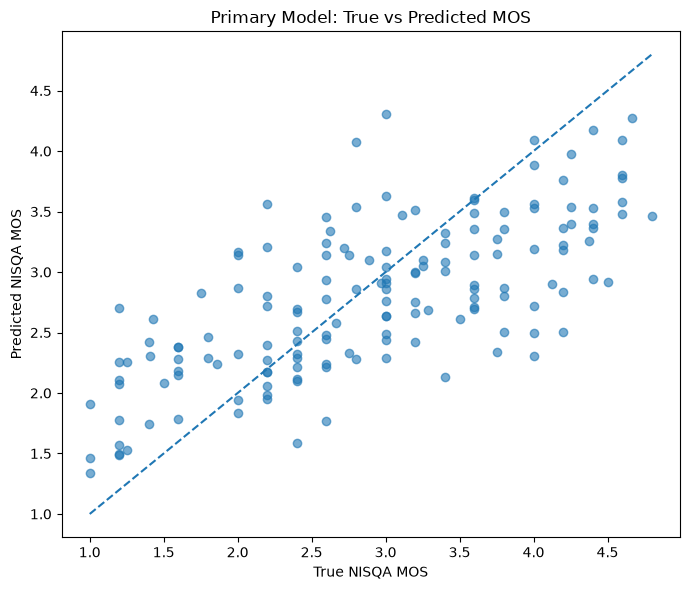

In [28]:
# ============================================================
# SECTION 25: PREDICTION DIAGNOSTICS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    primary_pred,
    alpha=0.6
)

lims = [
    min(y_test.min(), primary_pred.min()),
    max(y_test.max(), primary_pred.max())
]

plt.plot(
    lims,
    lims,
    linestyle="--"
)

plt.xlabel("True NISQA MOS")
plt.ylabel("Predicted NISQA MOS")
plt.title("Primary Model: True vs Predicted MOS")
plt.tight_layout()
plt.show()


In [29]:
# ============================================================
# SECTION 26: SAVE FINAL EXPERIMENT RESULTS
# ============================================================

results.to_csv(
    "model_comparison_results.csv",
    index=False
)

cv_df.to_csv(
    "group_cross_validation_results.csv",
    index=False
)

importance.to_csv(
    "primary_feature_importance.csv",
    index=False
)

print("Saved:")
print("- features_all.csv")
print("- model_comparison_results.csv")
print("- group_cross_validation_results.csv")
print("- primary_feature_importance.csv")


Saved:
- features_all.csv
- model_comparison_results.csv
- group_cross_validation_results.csv
- primary_feature_importance.csv


# Final interpretation

The experiment should be reported as an **acoustic speech-quality regression study using NISQA MOS**.

The comparison is:

- **Primary representation:** the project's handcrafted acoustic features.
- **External representation:** eGeMAPS.
- **Regressor:** XGBoost for both representations.
- **Evaluation:** MAE, RMSE and R².
- **Leakage control:** group-independent train/validation/test partitioning and GroupKFold cross-validation.

Do not call NISQA MOS an interview communication score. If the final project needs a validated interview-fluency score, a human-rated interview communication/fluency dataset is still required.
